In [6]:
pip -q install ultralytics

In [7]:
from collections import defaultdict
import cv2
import numpy as np
from ultralytics import YOLO
from pathlib import Path
from google.colab.patches import cv2_imshow
from IPython.display import clear_output

In [9]:
# Abrir el archivo de video
video_path = '/content/My-Movie.mp4'
cap = cv2.VideoCapture(video_path)

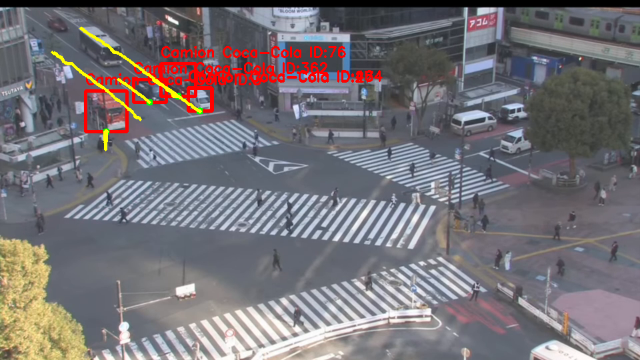

In [ ]:


# Cargar modelo YOLO preentrenado
model = YOLO('yolov8m.pt')

# Asegurar que el video se abra desde el inicio al ejecutar la celda
cap = cv2.VideoCapture('My-Movie.mp4')

rutas_coca = defaultdict(list)
ids_confirmados = set()

CLASES_VEHICULOS = list((2, 5, 7))

# Rangos HSV para rojo brillante (Coca-Cola)
ROJO_BAJO_1 = np.array((0, 110, 95), dtype=np.uint8)
ROJO_ALTO_1 = np.array((10, 255, 255), dtype=np.uint8)
ROJO_BAJO_2 = np.array((165, 110, 95), dtype=np.uint8)
ROJO_ALTO_2 = np.array((180, 255, 255), dtype=np.uint8)

def es_rojo_coca_cola(recorte_bgr, umbral_porcentaje=0.05):
    """Umbral al 5% para detectarlo incluso de frente o de espaldas."""
    if recorte_bgr.size == 0:
        return False

    hsv = cv2.cvtColor(recorte_bgr, cv2.COLOR_BGR2HSV)
    mascara1 = cv2.inRange(hsv, ROJO_BAJO_1, ROJO_ALTO_1)
    mascara2 = cv2.inRange(hsv, ROJO_BAJO_2, ROJO_ALTO_2)
    mascara_total = mascara1 + mascara2

    alto, ancho = recorte_bgr.shape[:2]
    area = alto * ancho
    if area == 0:
        return False

    proporcion = cv2.countNonZero(mascara_total) / area
    return proporcion >= umbral_porcentaje

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    results = model.track(
        frame,
        persist=True,
        classes=CLASES_VEHICULOS,
        conf=0.10,
        imgsz=1280,
        device=0,
        tracker='bytetrack.yaml',
        verbose=False
    )

    # Extraer el primer resultado de la lista de forma segura
    res = next(iter(results))

    if res.boxes is not None and res.boxes.id is not None:
        boxes_xyxy = res.boxes.xyxy.int().cpu().tolist()
        track_ids = res.boxes.id.int().cpu().tolist()

        for box, track_id in zip(boxes_xyxy, track_ids):
            x1, y1, x2, y2 = box
            recorte = frame[y1:y2, x1:x2]

            if track_id in ids_confirmados or es_rojo_coca_cola(recorte, umbral_porcentaje=0.05):
                ids_confirmados.add(track_id)

                suelo_x = int((x1 + x2) / 2)
                suelo_y = int(y2)

                rutas_coca[track_id].append((suelo_x, suelo_y))

                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 3)
                cv2.putText(frame, f"Camion Coca-Cola ID:{track_id}", (x1, y1 - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
                cv2.circle(frame, (suelo_x, suelo_y), 5, (0, 255, 0), -1)

    for track_id, puntos in rutas_coca.items():
        if len(puntos) > 1:
            pts = np.array(puntos, dtype=np.int32).reshape((-1, 1, 2))
            cv2.polylines(frame, list((pts,)), isClosed=False, color=(0, 255, 255), thickness=4)

    # Mostrar el fotograma en Colab sin saturar el navegador
    clear_output(wait=True)
    cv2_imshow(cv2.resize(frame, (640, 360)))

cap.release()
print("Proceso terminado.")


In [ ]:
# Cargar modelo YOLO preentrenado (yolov8s es rápido y preciso en T4)
model = YOLO('yolov8s.pt')

# Asegurar que el video se abra desde el inicio
cap = cv2.VideoCapture('My-Movie.mp4')

rutas_coca = defaultdict(list)
ids_confirmados = set()

# Definir clases usando tuplas (2: car, 5: bus, 7: truck)
CLASES_VEHICULOS = list((2, 5, 7))

# Definir rangos HSV para rojo brillante usando tuplas
ROJO_BAJO_1 = np.array((0, 110, 95), dtype=np.uint8)
ROJO_ALTO_1 = np.array((10, 255, 255), dtype=np.uint8)
ROJO_BAJO_2 = np.array((165, 110, 95), dtype=np.uint8)
ROJO_ALTO_2 = np.array((180, 255, 255), dtype=np.uint8)

def es_rojo_coca_cola(recorte_bgr, umbral_porcentaje=0.13):
    if recorte_bgr.size == 0:
        return False

    # Redimensionar el recorte a 32x32 acelera el cálculo de color en CPU sin perder precisión
    pequeno = cv2.resize(recorte_bgr, (32, 32))
    hsv = cv2.cvtColor(pequeno, cv2.COLOR_BGR2HSV)

    mascara1 = cv2.inRange(hsv, ROJO_BAJO_1, ROJO_ALTO_1)
    mascara2 = cv2.inRange(hsv, ROJO_BAJO_2, ROJO_ALTO_2)
    mascara_total = mascara1 + mascara2

    # 32 * 32 = 1024 píxeles totales
    proporcion = cv2.countNonZero(mascara_total) / 1024.0
    return proporcion >= umbral_porcentaje

contador = 0
SALTO_FRAMES = 2  # Procesa 1 de cada 2 fotogramas para duplicar velocidad

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    contador += 1
    if contador % SALTO_FRAMES != 0:
        continue

    # Estandarizar tamaño de entrada para mantener velocidad constante
    frame = cv2.resize(frame, (1280, 720))

    # Detección y rastreo con ByteTrack acelerado en GPU (half=True)
    results = model.track(
        frame,
        persist=True,
        classes=CLASES_VEHICULOS,
        conf=0.12,
        imgsz=640,
        half=True,
        tracker='bytetrack.yaml',
        verbose=False
    )

    res = results[0]

    if res.boxes is not None and res.boxes.id is not None:
        boxes_xyxy = res.boxes.xyxy.int().cpu().tolist()
        track_ids = res.boxes.id.int().cpu().tolist()

        for box, track_id in zip(boxes_xyxy, track_ids):
            x1, y1, x2, y2 = box

            if track_id in ids_confirmados or es_rojo_coca_cola(frame[y1:y2, x1:x2], umbral_porcentaje=0.13):
                ids_confirmados.add(track_id)

                suelo_x = int((x1 + x2) / 2)
                suelo_y = int(y2)

                rutas_coca[track_id].append((suelo_x, suelo_y))

                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 0, 255), 3)
                cv2.putText(frame, f"Camion Coca-Cola ID:{track_id}", (x1, y1 - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
                cv2.circle(frame, (suelo_x, suelo_y), 5, (0, 255, 0), -1)

    for track_id, puntos in rutas_coca.items():
        if len(puntos) > 1:
            pts = np.array(puntos, dtype=np.int32).reshape((-1, 1, 2))
            cv2.polylines(frame, list((pts,)), isClosed=False, color=(0, 255, 255), thickness=4)

    # Visualización en vivo compatible con Colab
    clear_output(wait=True)
    cv2_imshow(cv2.resize(frame, (640, 360)))

cap.release()
print("Procesamiento finalizado.")

